# Importing Libraries

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading dataset
df = pd.read_csv("credit_card_fraud.csv")

In [3]:
df.head()

,transaction_amount,transaction_amount_bin,avg_amount_deviation_sigma,merchant_category,merchant_risk_score,merchant_category_vs_history,geo_velocity_kmh,geo_velocity_bin,geo_distance_km,geo_distance_bin,...,account_credential_change_recency,card_present_cnp,order_shipping_speed,account_age_days,chargeback_history_count,customer_id,transaction_id,segment,customer_type,is_fraud
0,2.98,low,1.01,retail,medium_risk,rare_category,2.5,normal,9.9,same_location,...,no_recent_change,manual_entry,standard,1786,0,CUST_A_0083030,TXN_23_0088742,A_established,customer_based,0
1,49.69,low,0.62,travel,high_risk,frequent_category,2.2,normal,0.3,same_location,...,no_recent_change,card_present_swipe,expedited,1700,0,CUST_A_0036790,TXN_18_0167588,A_established,customer_based,0
2,3.21,low,1.25,travel,high_risk,frequent_category,1.7,normal,0.2,same_location,...,no_recent_change,contactless,expedited,3380,1,CUST_A_0020159,TXN_22_0179954,A_established,customer_based,0
3,66.24,medium,1.20,retail,medium_risk,frequent_category,3.2,normal,3.9,same_location,...,no_recent_change,cnp_online,standard,1630,0,CUST_A_0084812,TXN_8_0194016,A_established,customer_based,0
4,70.45,medium,0.23,retail,medium_risk,rare_category,4.4,normal,7.9,same_location,...,no_recent_change,card_present_swipe,expedited,2396,0,CUST_A_0013862,TXN_5_0049139,A_established,customer_based,0


# Data Characterisation

In [4]:
df.shape

(100000, 34)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   transaction_amount                 100000 non-null  float64
 1   transaction_amount_bin             100000 non-null  str    
 2   avg_amount_deviation_sigma         100000 non-null  float64
 3   merchant_category                  100000 non-null  str    
 4   merchant_risk_score                100000 non-null  str    
 5   merchant_category_vs_history       100000 non-null  str    
 6   geo_velocity_kmh                   100000 non-null  float64
 7   geo_velocity_bin                   100000 non-null  str    
 8   geo_distance_km                    100000 non-null  float64
 9   geo_distance_bin                   100000 non-null  str    
 10  merchant_location                  100000 non-null  str    
 11  country_consistency                100000 non-null 

In [6]:
df.describe()

,transaction_amount,avg_amount_deviation_sigma,geo_velocity_kmh,geo_distance_km,session_duration_sec,cards_on_device_30d,failed_attempts_before_success,account_age_days,chargeback_history_count,is_fraud
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000
mean,156.649608,1.313966,43.791450,90.422006,161.031714,2.033420,0.410360,1035.751310,0.152850,0.04901
std,352.326039,1.869456,216.882194,647.713371,157.039362,1.802564,1.031531,1105.295104,0.485849,0.21589
min,0.500000,0.000000,0.000000,0.000000,0.300000,1.000000,0.000000,0.000000,0.000000,0.00000
25%,29.230000,0.380000,1.900000,1.200000,65.800000,1.000000,0.000000,136.000000,0.000000,0.00000
50%,67.405000,0.780000,3.800000,2.400000,116.100000,2.000000,0.000000,551.000000,0.000000,0.00000
75%,154.790000,1.330000,16.800000,12.100000,202.400000,2.000000,0.000000,1836.000000,0.000000,0.00000
max,9999.000000,10.000000,2497.400000,7996.200000,1800.000000,17.000000,10.000000,3649.000000,3.000000,1.00000


In [7]:
df.isnull().sum()

transaction_amount                   0
transaction_amount_bin               0
avg_amount_deviation_sigma           0
merchant_category                    0
merchant_risk_score                  0
merchant_category_vs_history         0
geo_velocity_kmh                     0
geo_velocity_bin                     0
geo_distance_km                      0
geo_distance_bin                     0
merchant_location                    0
country_consistency                  0
ip_address_type                      0
device_fingerprint_match             0
session_duration_sec                 0
session_duration_bin                 0
network_carrier_type                 0
cards_on_device_30d                  0
cvv_match_status                     0
three_ds_auth_result                 0
tokenization_used                    0
failed_attempts_before_success       0
transaction_velocity_1h              0
time_of_transaction                  0
account_credential_change_recency    0
card_present_cnp         

In [8]:
df.duplicated().sum()

np.int64(0)

# Data Cleaning 

In [9]:
# Standardise Text
df.columns = df.columns.str.strip()

# Analysing categorical variables

In [10]:
df["transaction_amount_bin"].value_counts()

transaction_amount_bin
medium       53932
low          40384
high          5101
very_high      583
Name: count, dtype: int64

In [11]:
df["transaction_amount_bin"].unique()

<ArrowStringArray>
['low', 'medium', 'high', 'very_high']
Length: 4, dtype: str

In [12]:
transaction_amount_bin_corrections = {

   "very_high":"high"

}

df["transaction_amount_bin"] = df["transaction_amount_bin"].replace(
    transaction_amount_bin_corrections 
)

In [13]:
df["transaction_amount_bin"].value_counts()

transaction_amount_bin
medium    53932
low       40384
high       5684
Name: count, dtype: int64

In [14]:
df["merchant_category"].value_counts()

merchant_category
grocery            20407
retail             18610
travel             11596
utility            11481
electronics        11074
restaurant         10762
healthcare          6145
luxury              5371
crypto_giftcard     4554
Name: count, dtype: int64

In [15]:
df["merchant_risk_score"].value_counts()

merchant_risk_score
low_risk          38033
medium_risk       29372
high_risk         22670
very_high_risk     9925
Name: count, dtype: int64

In [16]:
df["merchant_risk_score"].unique()

<ArrowStringArray>
['medium_risk', 'high_risk', 'low_risk', 'very_high_risk']
Length: 4, dtype: str

In [17]:
merchant_risk_score_corrections = {

   "very_high_risk":"high_risk"

}

df["merchant_risk_score"] = df["merchant_risk_score"].replace(
    merchant_risk_score_corrections 
)

In [18]:
df["merchant_risk_score"].value_counts()

merchant_risk_score
low_risk       38033
high_risk      32595
medium_risk    29372
Name: count, dtype: int64

In [19]:
df["merchant_category_vs_history"].value_counts()

merchant_category_vs_history
frequent_category        64610
rare_category            17344
no_history               10074
occasional_category       5480
never_before_category     2492
Name: count, dtype: int64

In [20]:
df["geo_velocity_bin"].value_counts()

geo_velocity_bin
normal        88483
fast           9668
impossible     1849
Name: count, dtype: int64

In [21]:
df["geo_distance_bin"].value_counts()

geo_distance_bin
same_location    93388
short             4763
long              1849
Name: count, dtype: int64

In [22]:
df["merchant_location"].value_counts()

merchant_location
home_city              57861
same_country           24321
neighboring_country    11055
foreign_far             6763
Name: count, dtype: int64

In [23]:
df["country_consistency"].value_counts()

country_consistency
same_country               69242
frequent_travel_country    15689
new_country                11154
high_risk_country           3915
Name: count, dtype: int64

In [24]:
df["ip_address_type"].value_counts()

ip_address_type
residential    62243
corporate      17225
vpn             8169
proxy           5221
datacenter      4858
tor             2284
Name: count, dtype: int64

In [25]:
df["device_fingerprint_match"].value_counts()

device_fingerprint_match
known_device      70546
new_device        16614
unknown_device     6287
emulator           4006
spoofed            2547
Name: count, dtype: int64

In [26]:
df["session_duration_bin"].value_counts()

session_duration_bin
normal       63282
slow         29651
very_fast     4567
bot_speed     2500
Name: count, dtype: int64

In [27]:
df["network_carrier_type"].value_counts()

network_carrier_type
wifi                  44034
mobile_data           36875
corporate_vpn         11316
datacenter_hosting     7775
Name: count, dtype: int64

In [28]:
df["cvv_match_status"].value_counts()

cvv_match_status
cvv2_match       72833
icvv_match       14476
not_provided      6625
cvv2_mismatch     6066
Name: count, dtype: int64

In [29]:
df["three_ds_auth_result"].value_counts()

three_ds_auth_result
frictionless_pass    47815
challenge_pass       26882
not_enrolled         12609
bypassed              8059
challenge_fail        4635
Name: count, dtype: int64

In [30]:
df["tokenization_used"].value_counts()

tokenization_used
network_token_wallet    26799
raw_pan_online          23450
emv_chip_token          23084
issuer_token            16991
raw_pan_manual_entry     9676
Name: count, dtype: int64

In [31]:
df["transaction_velocity_1h"].value_counts()

transaction_velocity_1h
within_normal    74480
2x_baseline      13832
5x_baseline       6628
burst_pattern     5060
Name: count, dtype: int64

In [32]:
df["time_of_transaction"].value_counts()

time_of_transaction
afternoon_12_18    33867
evening_18_24      28001
morning_6_12       27021
late_night_0_5     11111
Name: count, dtype: int64

In [33]:
df["account_credential_change_recency"].value_counts()

account_credential_change_recency
no_recent_change      73998
not_applicable        10074
changed_7_30d_ago      7188
changed_1_7d_ago       4491
changed_within_24h     4249
Name: count, dtype: int64

In [34]:
df["card_present_cnp"].value_counts()

card_present_cnp
card_present_chip     28732
contactless           26820
cnp_online            20133
card_present_swipe    14227
cnp_moto               5581
manual_entry           4507
Name: count, dtype: int64

In [35]:
df["order_shipping_speed"].value_counts()

order_shipping_speed
standard           45702
expedited          24462
overnight          11310
same_day            9592
in_store_pickup     8934
Name: count, dtype: int64

In [36]:
df["segment"].value_counts()

segment
A_established    40177
B_regular        29765
C_new            19984
D_guest          10074
Name: count, dtype: int64

In [37]:
df["customer_type"].value_counts()

customer_type
customer_based    89926
global            10074
Name: count, dtype: int64

# Analysing Target Variable

In [38]:
df["is_fraud"].value_counts()

is_fraud
0    95099
1     4901
Name: count, dtype: int64

In [39]:
fraud_percentage = (df['is_fraud'].value_counts(normalize=True) * 100)
fraud_percentage

is_fraud
0    95.099
1     4.901
Name: proportion, dtype: float64

# Exploratory Data Analysis (EDA)

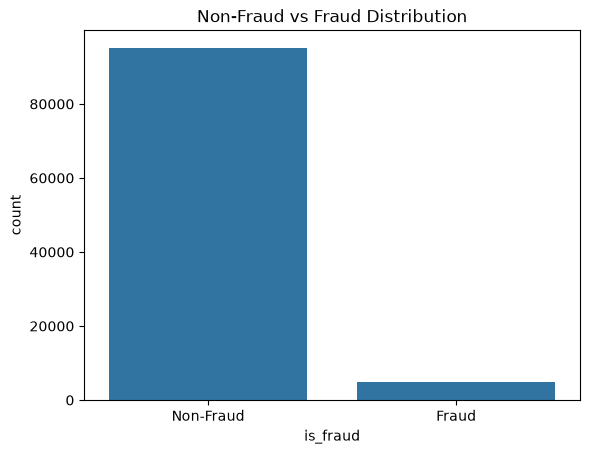

In [40]:
sns.countplot(data=df, x='is_fraud')

plt.xticks([0, 1],['Non-Fraud', 'Fraud'])

plt.title('Non-Fraud vs Fraud Distribution')
plt.show()

# Correlation Heatmap

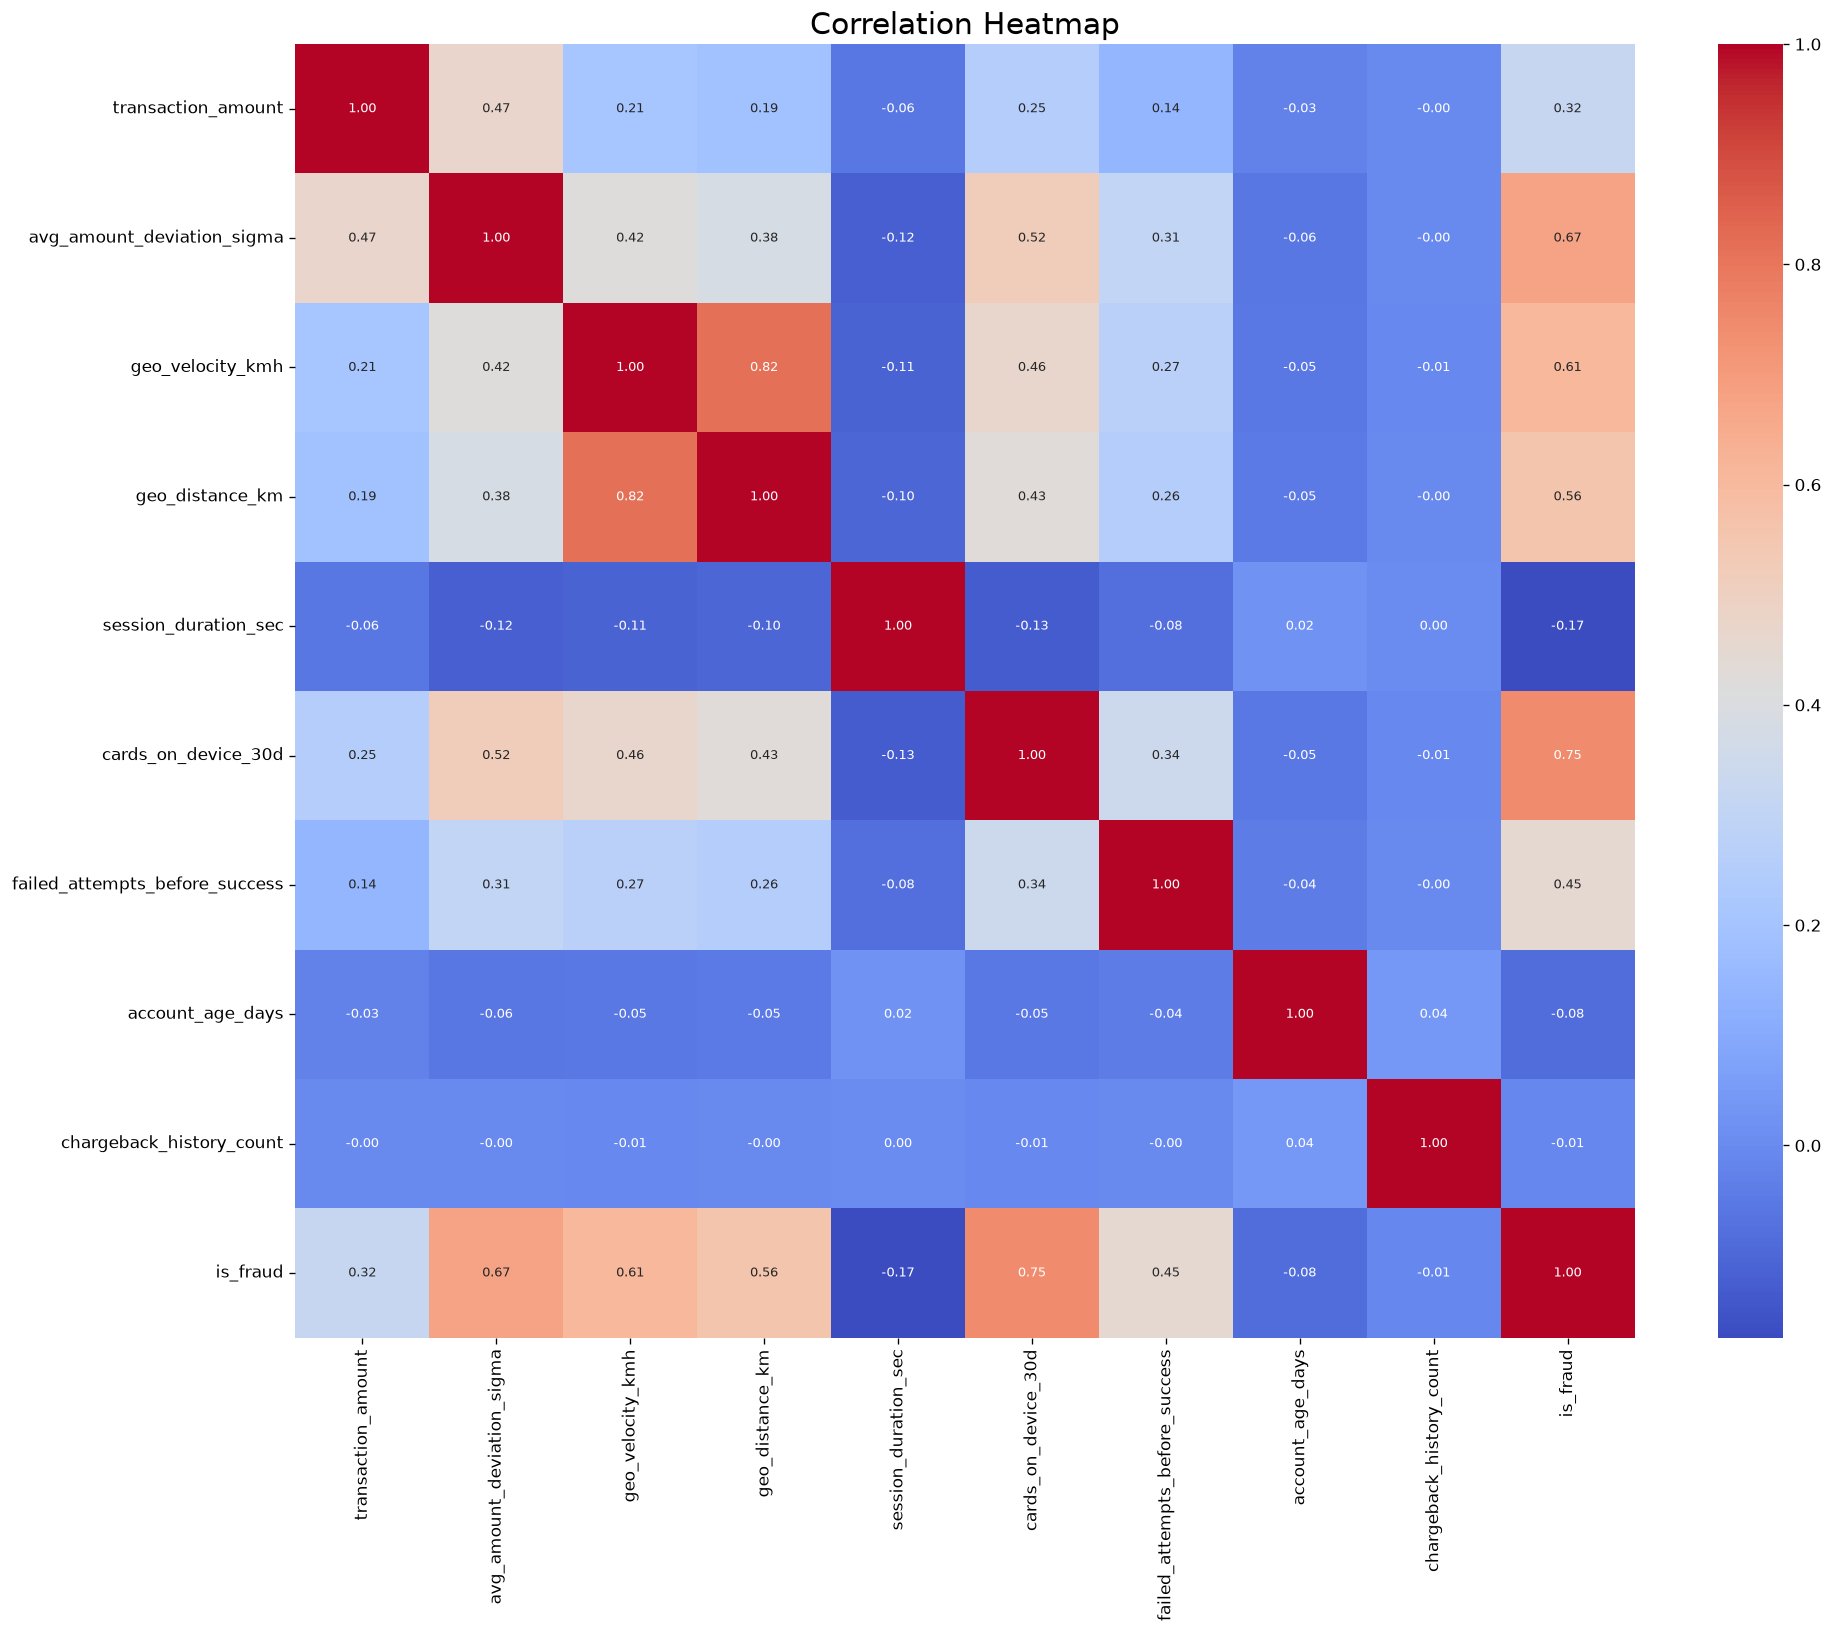

In [41]:
plt.figure(figsize=(18, 14), dpi=120)

# Select only numerical columns
corr = df.select_dtypes(include=['number']).corr()

sns.heatmap(corr,annot=True,fmt=".2f",cmap="coolwarm",annot_kws={"size": 8})

plt.title("Correlation Heatmap", fontsize=18)
plt.show()

# Merchant Category Analysis

In [42]:
merchant_fraud = pd.crosstab(df['merchant_category'],df['is_fraud'],normalize='index')

merchant_fraud

is_fraud,0,1
merchant_category,,
crypto_giftcard,0.736056,0.263944
electronics,0.860936,0.139064
grocery,0.993777,0.006223
healthcare,0.980635,0.019365
luxury,0.777323,0.222677
restaurant,0.979836,0.020164
retail,0.987426,0.012574
travel,0.982321,0.017679
utility,0.994687,0.005313


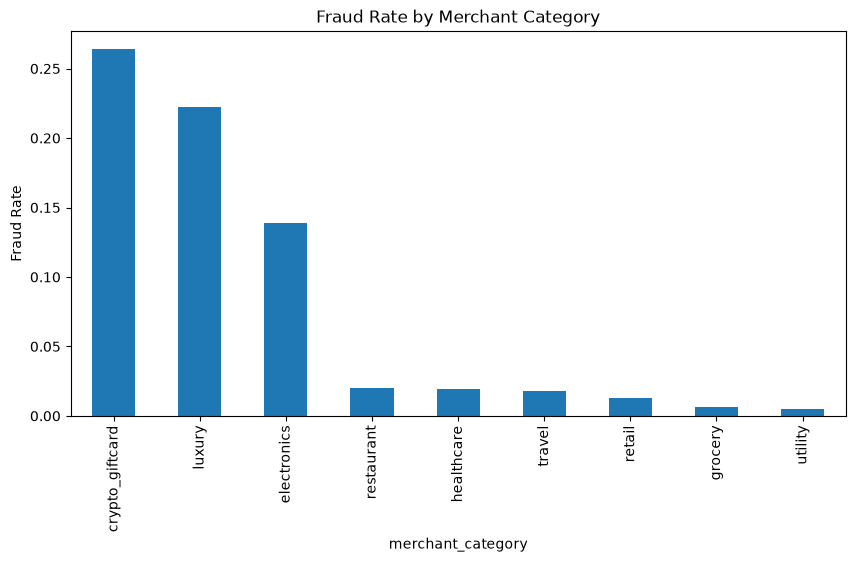

In [43]:
merchant_fraud[1].sort_values(ascending=False).plot(kind='bar',figsize=(10,5))

plt.title('Fraud Rate by Merchant Category')

plt.ylabel('Fraud Rate')

plt.show()

# Merchant Risk Score Analysis

In [44]:
merchant_risk = pd.crosstab(df['merchant_risk_score'],df['is_fraud'],normalize='index')

merchant_risk

is_fraud,0,1
merchant_risk_score,,
high_risk,0.872895,0.127105
low_risk,0.991928,0.008072
medium_risk,0.984645,0.015355


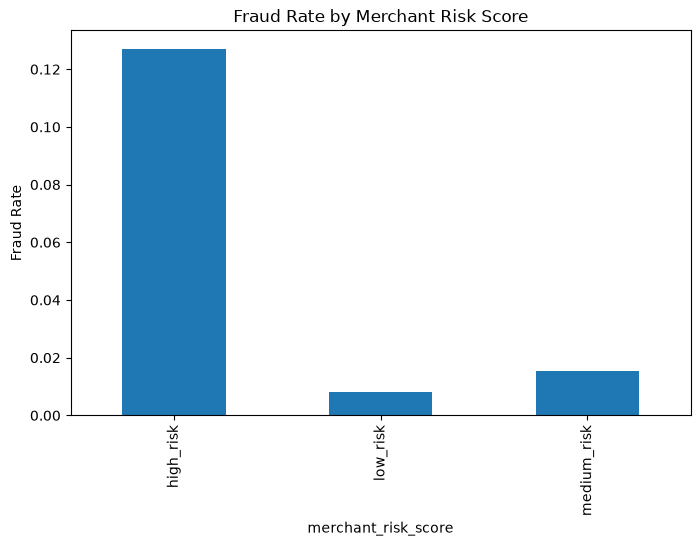

In [45]:
merchant_risk[1].plot(kind='bar',figsize=(8,5))

plt.title('Fraud Rate by Merchant Risk Score')

plt.ylabel('Fraud Rate')

plt.show()

# Time of Transaction Analysis

In [46]:
time_analysis = pd.crosstab(df['time_of_transaction'],df['is_fraud'],normalize='index')

time_analysis

is_fraud,0,1
time_of_transaction,,
afternoon_12_18,0.984262,0.015738
evening_18_24,0.949288,0.050712
late_night_0_5,0.766178,0.233822
morning_6_12,0.987047,0.012953


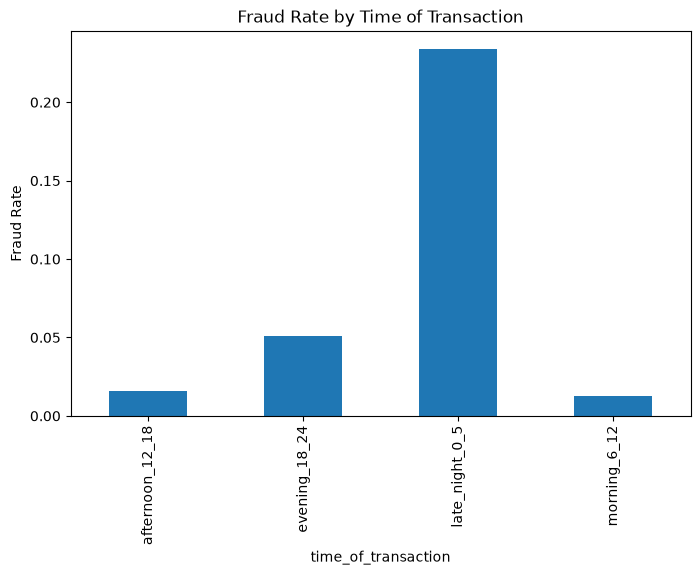

In [47]:
time_analysis[1].plot(kind='bar',figsize=(8,5))

plt.title('Fraud Rate by Time of Transaction')

plt.ylabel('Fraud Rate')

plt.show()

# Boxplots for Outlier 

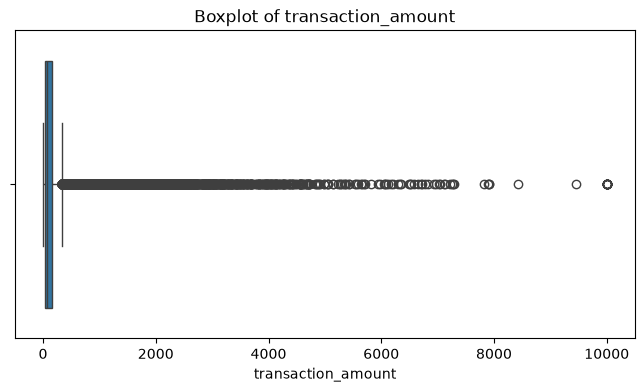

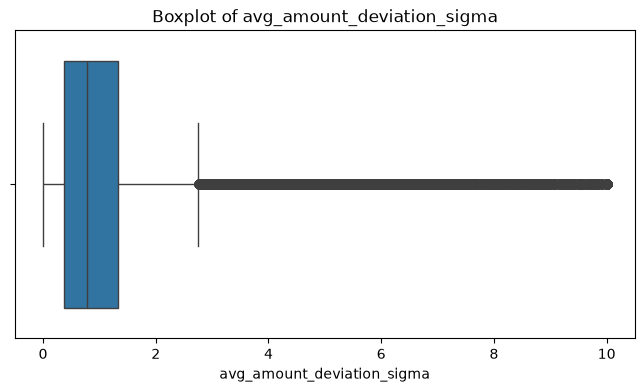

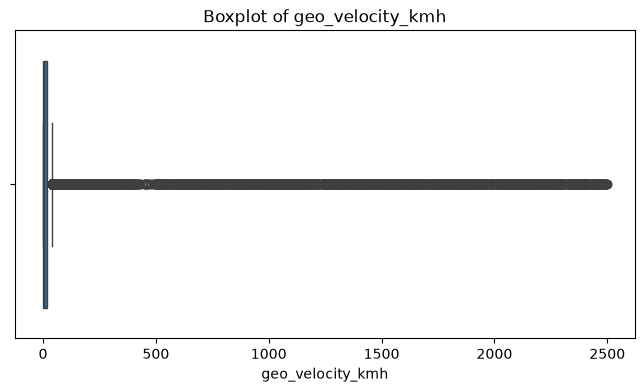

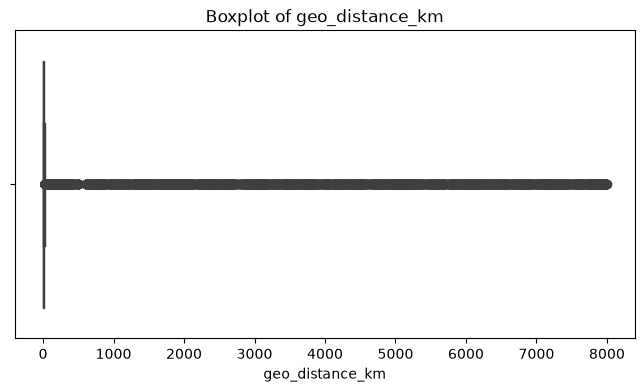

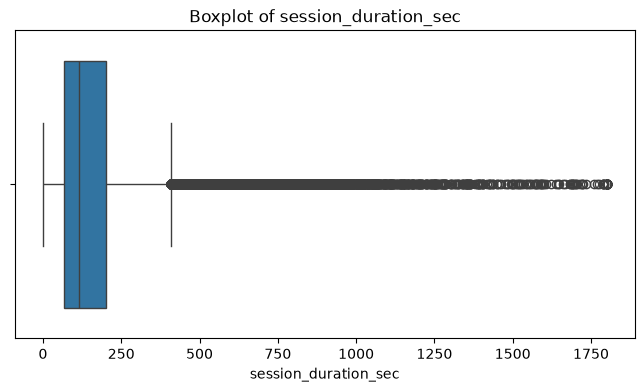

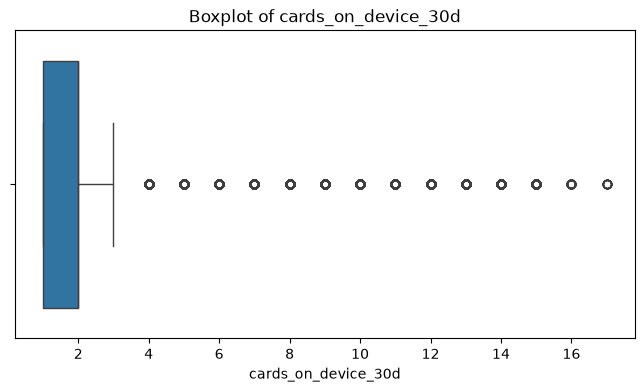

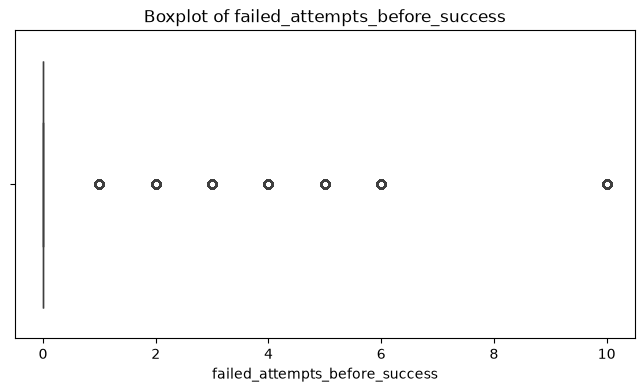

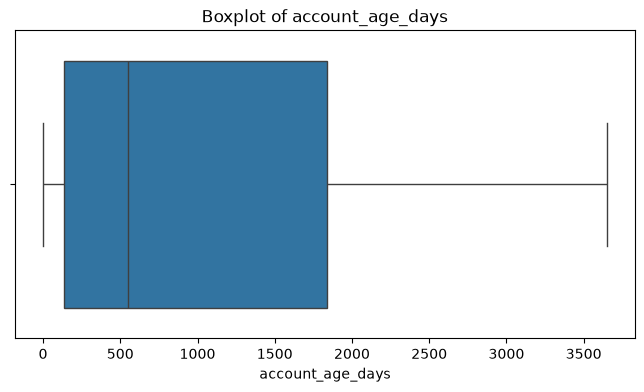

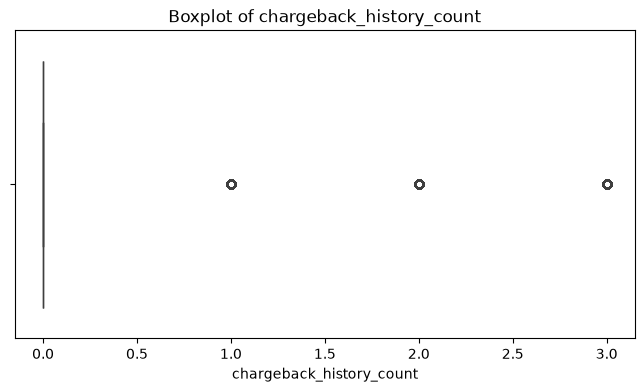

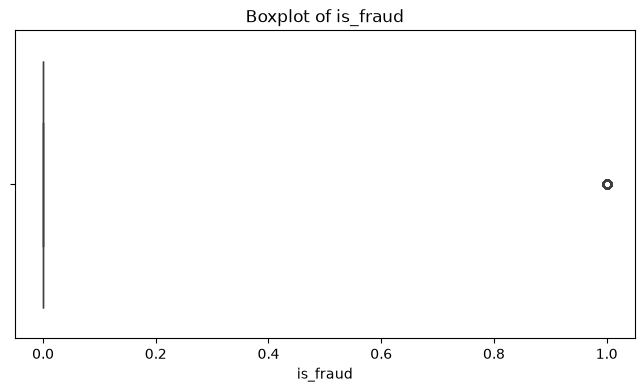

In [48]:
numerical_columns = df.select_dtypes(include=['number']).columns

for col in numerical_columns:
    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col}')

    plt.show()

# Country Consistency Analysis

In [49]:
country_analysis = pd.crosstab(df['country_consistency'],df['is_fraud'],normalize='index')

country_analysis

is_fraud,0,1
country_consistency,,
frequent_travel_country,0.964752,0.035248
high_risk_country,0.475607,0.524393
new_country,0.848126,0.151874
same_country,0.991320,0.008680


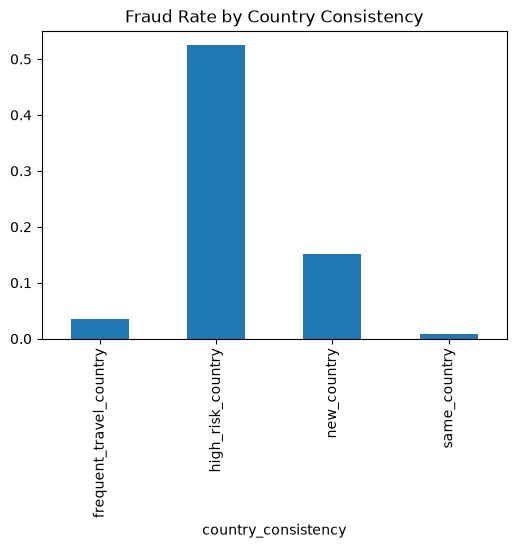

In [50]:
country_analysis[1].plot(kind='bar',figsize=(6,4))

plt.title('Fraud Rate by Country Consistency')

plt.show()

# Device Fingerprint Analysis

In [51]:
device_analysis = pd.crosstab(df['device_fingerprint_match'],df['is_fraud'],normalize='index')

device_analysis

is_fraud,0,1
device_fingerprint_match,,
emulator,0.488268,0.511732
known_device,0.996357,0.003643
new_device,0.971891,0.028109
spoofed,0.369062,0.630938
unknown_device,0.917290,0.082710


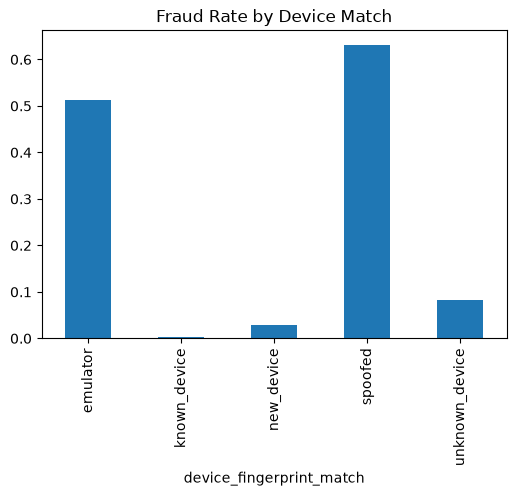

In [52]:
device_analysis[1].plot(kind='bar',figsize=(6,4))

plt.title('Fraud Rate by Device Match')

plt.show()

# Shipping Speed Analysis

In [53]:
shipping_analysis = pd.crosstab(df['order_shipping_speed'],df['is_fraud'],normalize='index')

shipping_analysis

is_fraud,0,1
order_shipping_speed,,
expedited,0.976903,0.023097
in_store_pickup,0.969778,0.030222
overnight,0.838285,0.161715
same_day,0.798165,0.201835
standard,0.993414,0.006586


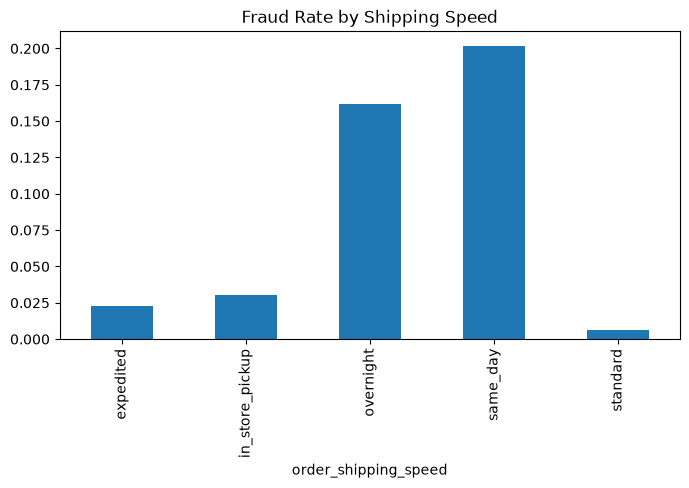

In [54]:
shipping_analysis[1].plot(kind='bar',figsize=(8,4))

plt.title('Fraud Rate by Shipping Speed')

plt.show()

# Customer Segment Analysis

In [55]:
segment_analysis = pd.crosstab(df['segment'],df['is_fraud'],normalize='index')

segment_analysis

is_fraud,0,1
segment,,
A_established,0.973094,0.026906
B_regular,0.958240,0.041760
C_new,0.930294,0.069706
D_guest,0.882470,0.117530


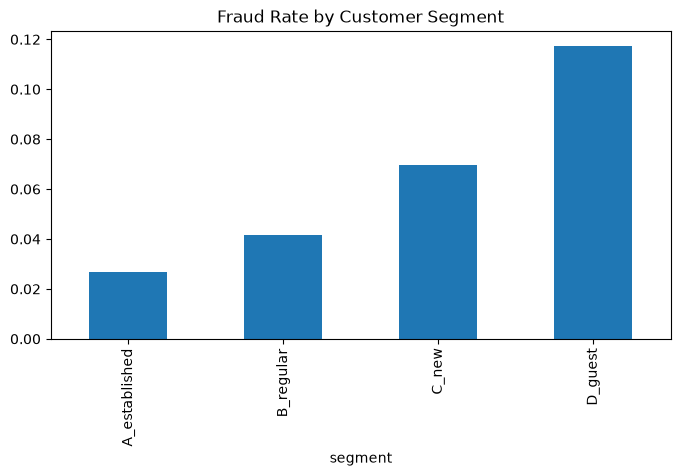

In [56]:
segment_analysis[1].plot(kind='bar',figsize=(8,4))

plt.title('Fraud Rate by Customer Segment')

plt.show()

# Customer Type Analysis

In [57]:
customer_type_analysis = pd.crosstab(df['customer_type'],df['is_fraud'],normalize='index')

customer_type_analysis

is_fraud,0,1
customer_type,,
customer_based,0.958666,0.041334
global,0.882470,0.117530


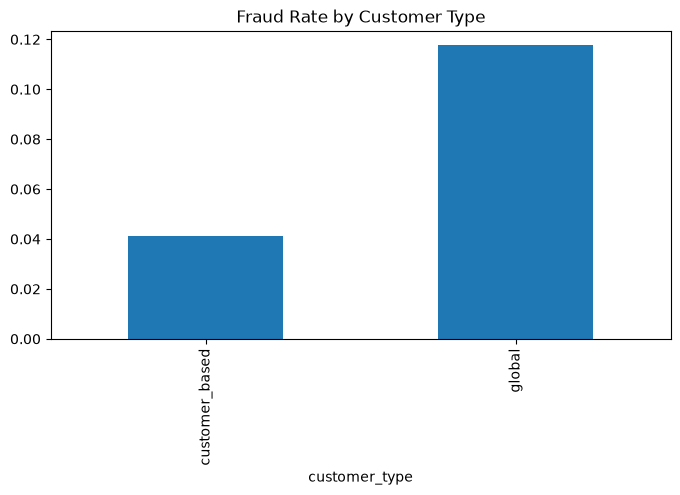

In [58]:
customer_type_analysis[1].plot(kind='bar',figsize=(8,4))

plt.title('Fraud Rate by Customer Type')

plt.show()

# Transaction Velocity Analysis

In [59]:
velocity_analysis = pd.crosstab(df['transaction_velocity_1h'],df['is_fraud'],normalize='index')

velocity_analysis

is_fraud,0,1
transaction_velocity_1h,,
2x_baseline,0.962551,0.037449
5x_baseline,0.727821,0.272179
burst_pattern,0.561067,0.438933
within_normal,0.995193,0.004807


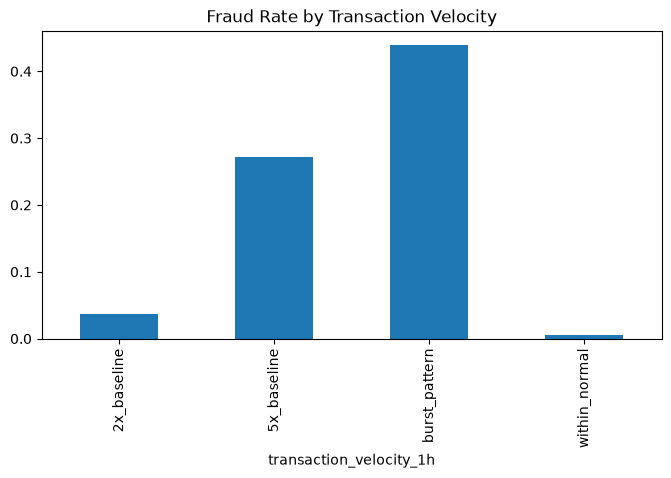

In [60]:
velocity_analysis[1].plot(kind='bar',figsize=(8,4))

plt.title('Fraud Rate by Transaction Velocity')

plt.show()

# CVV Match Analysis

In [61]:
cvv_analysis = pd.crosstab(df['cvv_match_status'],df['is_fraud'],normalize='index')

cvv_analysis

is_fraud,0,1
cvv_match_status,,
cvv2_match,0.993725,0.006275
cvv2_mismatch,0.625288,0.374712
icvv_match,0.980865,0.019135
not_provided,0.714113,0.285887


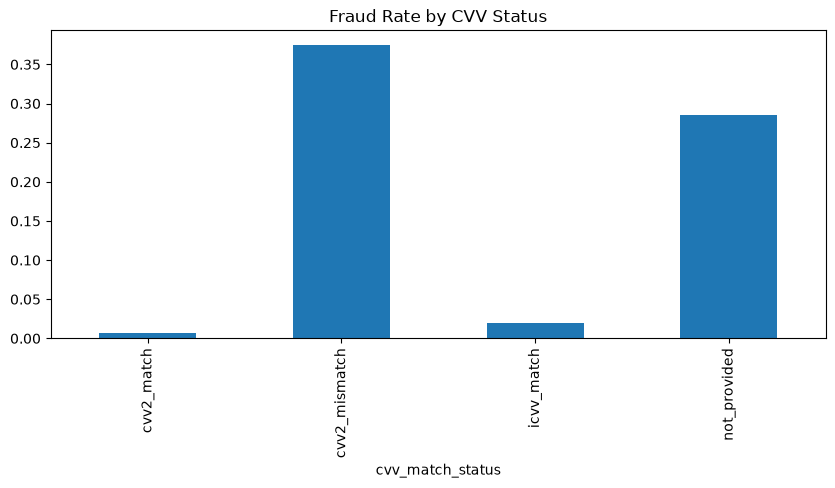

In [62]:
cvv_analysis[1].plot(kind='bar',figsize=(10,4))

plt.title('Fraud Rate by CVV Status')

plt.show()

# 3D Secure Analysis

In [63]:
three_ds_analysis = pd.crosstab(df['three_ds_auth_result'],df['is_fraud'],normalize='index')

three_ds_analysis

is_fraud,0,1
three_ds_auth_result,,
bypassed,0.824296,0.175704
challenge_fail,0.630421,0.369579
challenge_pass,0.991742,0.008258
frictionless_pass,0.993328,0.006672
not_enrolled,0.902371,0.097629


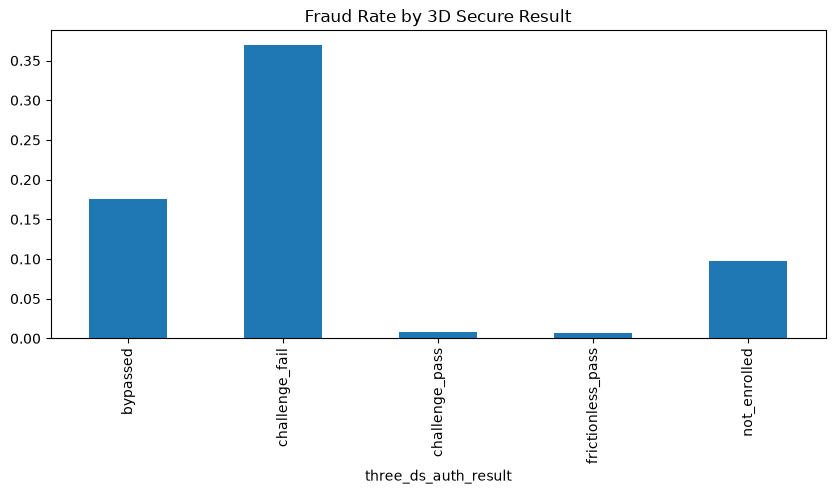

In [64]:
three_ds_analysis[1].plot(kind='bar',figsize=(10,4))

plt.title('Fraud Rate by 3D Secure Result')

plt.show()

# Treating outliers

In [65]:
numerical_features = [
    'transaction_amount',
    'avg_amount_deviation_sigma',
    'geo_velocity_kmh',
    'geo_distance_km',
    'session_duration_sec',
    'cards_on_device_30d',
    'failed_attempts_before_success',
    'account_age_days',
    'chargeback_history_count'
]

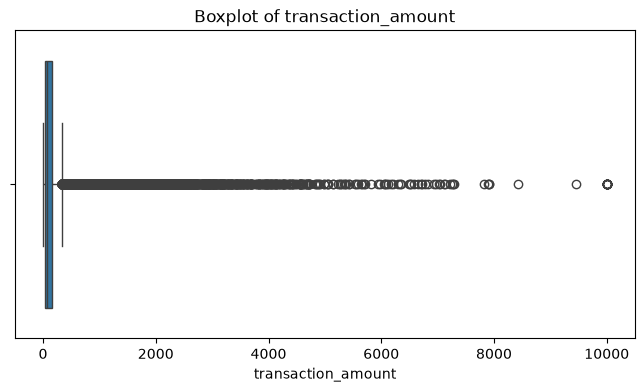

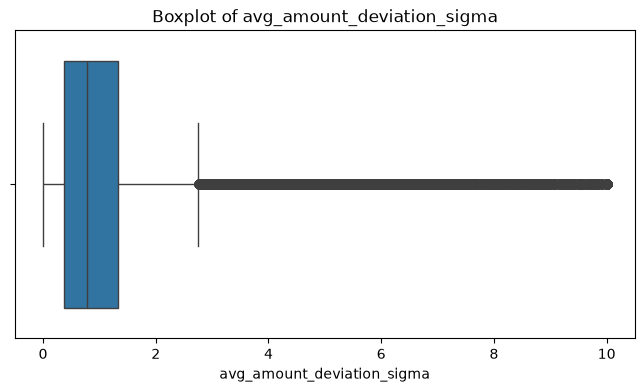

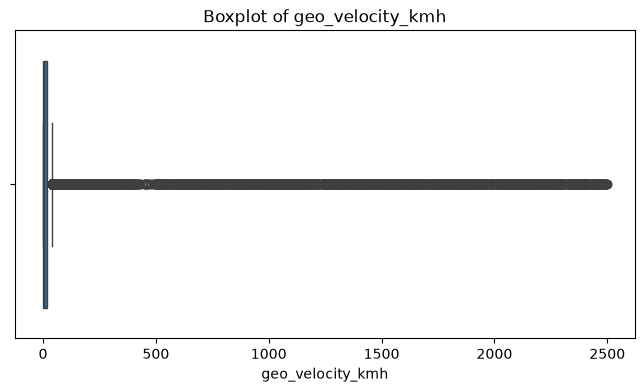

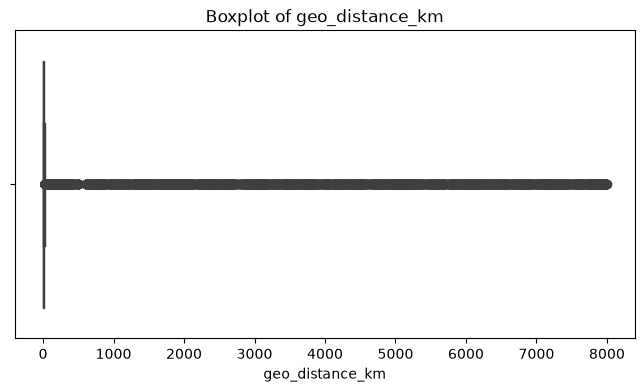

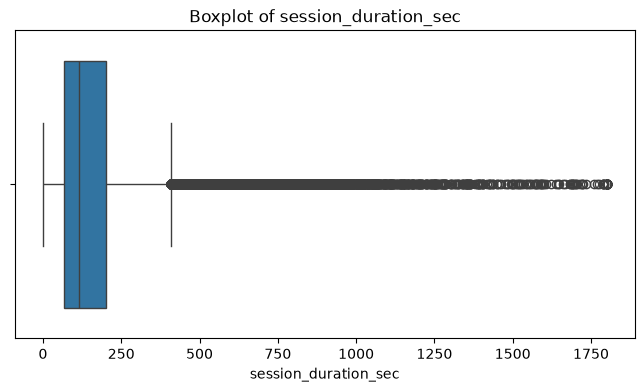

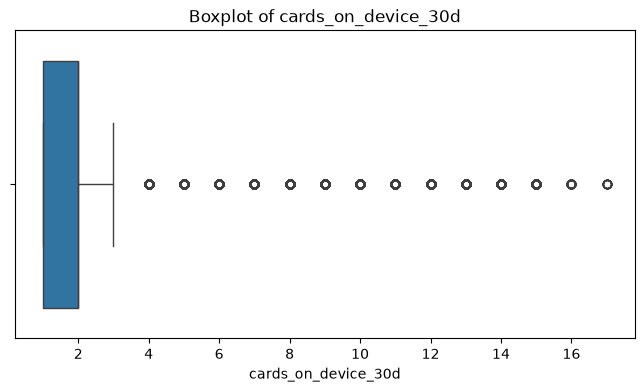

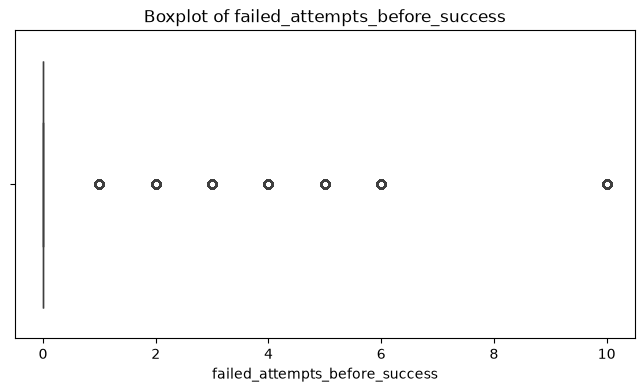

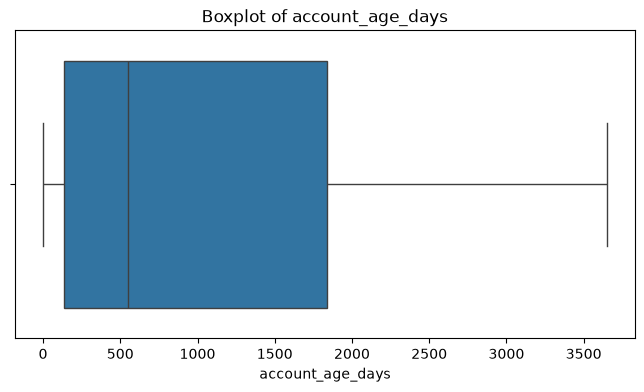

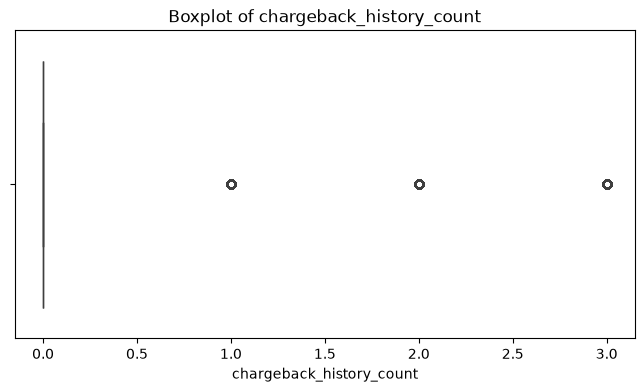

In [66]:
for column in numerical_features:

    plt.figure(figsize=(8,4))

    sns.boxplot(x=df[column])

    plt.title(f'Boxplot of {column}')

    plt.show()

# Calculate Outliers Using IQR

In [67]:
df_outlier = df.copy()

for column in numerical_features:

    Q1 = df[column].quantile(0.25)

    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR

    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} outliers")

transaction_amount: 9767 outliers
avg_amount_deviation_sigma: 9875 outliers
geo_velocity_kmh: 14701 outliers
geo_distance_km: 12945 outliers
session_duration_sec: 6303 outliers
cards_on_device_30d: 6075 outliers
failed_attempts_before_success: 20798 outliers
account_age_days: 0 outliers
chargeback_history_count: 10824 outliers


# Treating outliers with Winsorisation/percentile capping

In [68]:
for column in numerical_features:

    lower = df[column].quantile(0.01)

    upper = df[column].quantile(0.99)

    df[column] = np.clip(df[column],lower,upper)

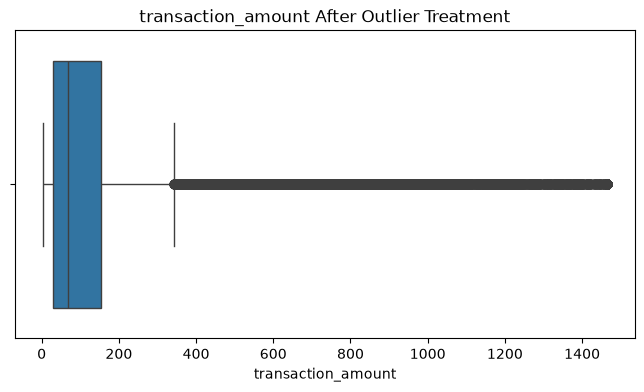

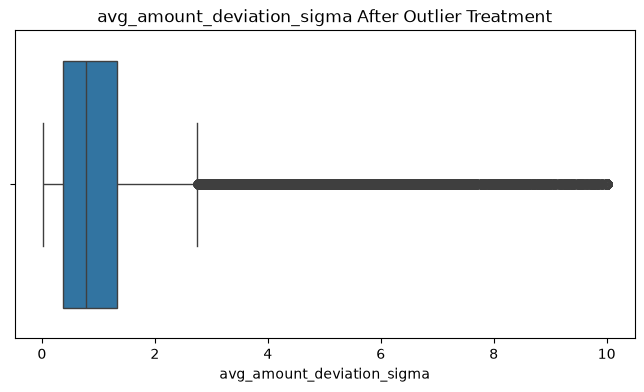

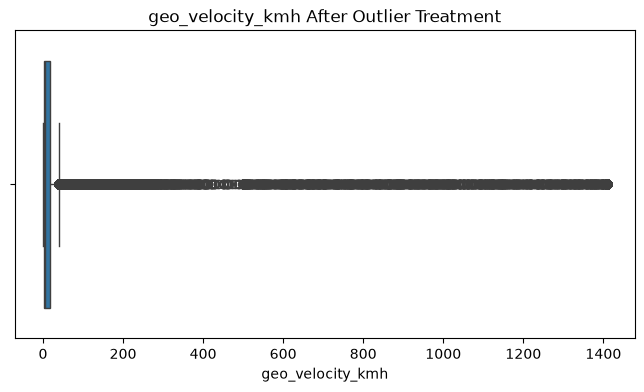

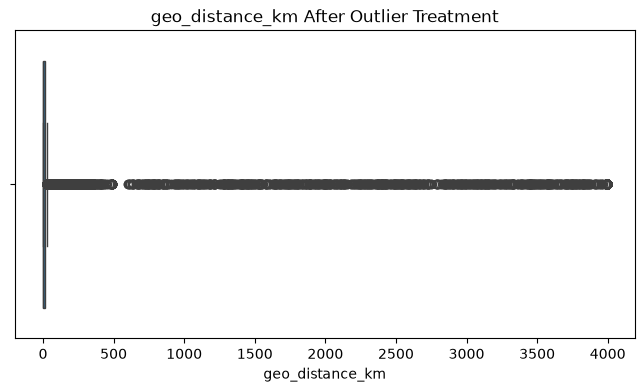

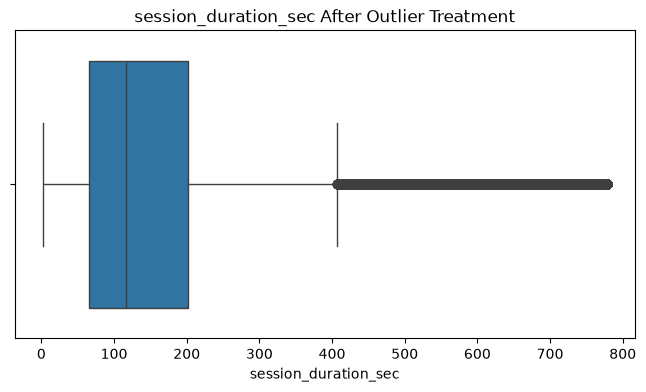

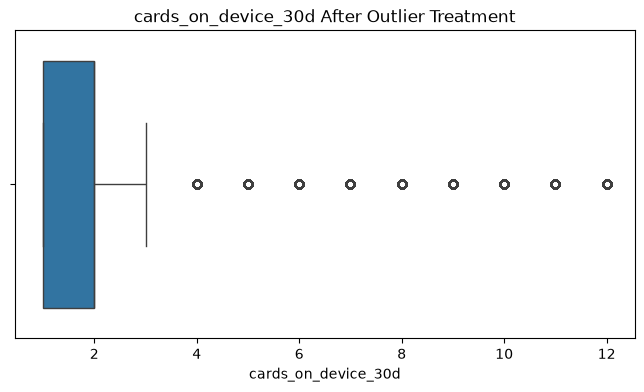

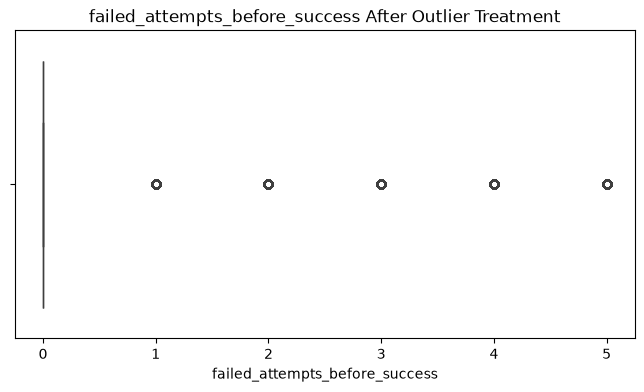

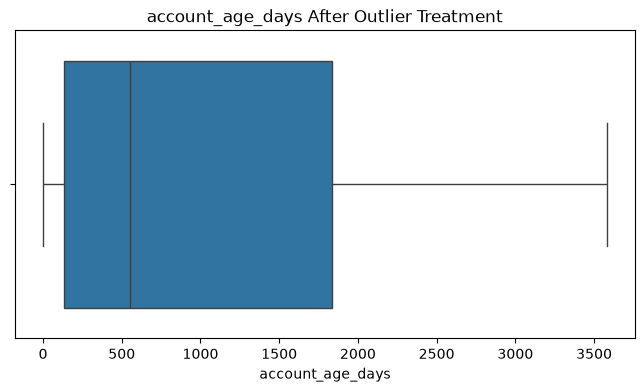

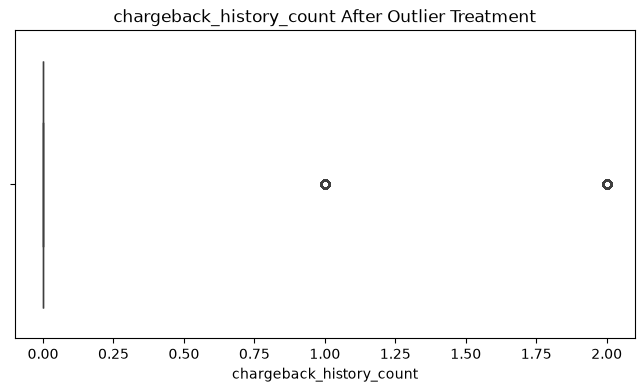

In [69]:
for column in numerical_features:

    plt.figure(figsize=(8,4))

    sns.boxplot(x=df[column])

    plt.title(f'{column} After Outlier Treatment')

    plt.show()

Outliers were identified using the Interquartile Range (IQR) method. Some variables had a high number of outliers, including failed_attempts_before_success (20.8%), geo_velocity_kmh (14.7%), and geo_distance_km (12.9%).

Since this is a fraud detection project, these unusual values were not automatically considered errors. They could represent suspicious activities that may help identify fraud. Therefore, instead of deleting these records, Winsorisation (capping extreme values at certain percentiles) was chosen to reduce the effect of outliers while keeping the important information in the dataset